# Module End  Assignment: Python For Data Analysis


## Social Media Engagement Analytics

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

import warnings
warnings.filterwarnings('ignore')

### Task 1 — Data Import & Setup

In [2]:
url = "https://raw.githubusercontent.com/GeethaGunasekaran1/Dataset_rep/main/social_media_engagement_5000.csv"

df = pd.read_csv(url)

df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [8]:
df.dtypes

user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
dtype: object

In [9]:
df['posted_at'] = pd.to_datetime(
    df['posted_at'],
    format='%d-%m-%Y',
    errors='coerce'
)

df['posted_at'].head()

0   2022-12-17
1   2023-06-02
2   2023-05-07
3   2023-02-12
4   2023-05-23
Name: posted_at, dtype: datetime64[us]

In [11]:
array_ops = df['likes'].dropna().to_numpy()

print("First 5 likes:", array_ops[:5])
print("Average likes:", np.mean(array_ops))
print("Maximum likes:", np.max(array_ops))
print("Minimum likes:", np.min(array_ops))

First 5 likes: [ 7011. 11750.  4862.  5350. 12682.]
Average likes: 10107.043711340206
Maximum likes: 19998.0
Minimum likes: 10.0


In [12]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='str')

### Task 2 — Data Cleaning

In [13]:
df.isnull().sum()

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

In [ ]:
Unique values - category

In [16]:
for col in df.select_dtypes(include='object').columns: 
    print("\nColumn:", col)
    print(df[col].unique())


Column: gender
<ArrowStringArray>
['Female', 'Male', 'Other', nan]
Length: 4, dtype: str

Column: country
<ArrowStringArray>
[   'Brazil',        'UK',    'France',    'Canada',     'Japan', 'Australia',
     'India',       'UAE',   'Germany',       'USA']
Length: 10, dtype: str

Column: post_type
<ArrowStringArray>
['image', 'reel', 'text', 'video']
Length: 4, dtype: str

Column: post_category
<ArrowStringArray>
[  'fitness',      'food',      'tech',    'travel',   'fashion', 'lifestyle',
 'education',     'music']
Length: 8, dtype: str

Column: device_type
<ArrowStringArray>
['mobile', 'tablet', 'desktop']
Length: 3, dtype: str

Column: sentiment
<ArrowStringArray>
['negative', 'positive', 'neutral', nan]
Length: 4, dtype: str

Column: hashtags
<ArrowStringArray>
[      '#foodie #travel #love',                    '#fitness',
                     '#foodie',         '#music #foodie #fun',
                     '#travel',                      '#music',
     '#travel #music #fitness',  

In [17]:
df.select_dtypes(include=np.number).columns

Index(['user_id', 'age', 'post_id', 'likes', 'comments', 'shares',
       'watch_time_sec', 'impression_count', 'follower_count',
       'engagement_rate'],
      dtype='str')

In [18]:
num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(include='object').columns

print("Numerical Columns:", list(num_cols))
print("Categorical Columns:", list(cat_cols))

Numerical Columns: ['user_id', 'age', 'post_id', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'follower_count', 'engagement_rate']
Categorical Columns: ['gender', 'country', 'post_type', 'post_category', 'device_type', 'sentiment', 'hashtags']


In [20]:
for col in num_cols:   #using median fill missing values in numeric columns
    df[col] = df[col].fillna(df[col].median())

In [22]:
for col in cat_cols: # using mode fill missing values in categorical columns
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

In [23]:
df_fill = df.copy()

df_fill = df_fill.ffill()

df_fill = df_fill.bfill()

df.isnull().sum()

### Duplicate Handling

In [25]:
df.isnull().sum()

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64

### Data Formatting

Standardize categories (e.g., gender labels)

In [28]:
for col in cat_cols:
    df[col] = df[col].apply(
        lambda x: x.strip().lower() if isinstance(x, str) else x
    )

In [31]:
engagement_cols = ['likes', 'comments', 'shares', 'impression_count']

for col in engagement_cols:
    print(col, "Negative values:", (df[col] < 0).sum())

likes Negative values: 0
comments Negative values: 0
shares Negative values: 0
impression_count Negative values: 0


 ### Feature Cleaning

In [32]:
df['hashtags'].head(10)

0      #foodie #travel #love
1                   #fitness
2                    #foodie
3        #music #foodie #fun
4                    #travel
5                   #fitness
6                     #music
7    #travel #music #fitness
8       #music #fun #fitness
9           #lifestyle #love
Name: hashtags, dtype: str

In [34]:
df['hashtag_count'] = df['hashtags'].apply(
    lambda x: len(str(x).split()) if pd.notna(x) else 0
)
df[['hashtags', 'hashtag_count']].head(10)

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1
5,#fitness,1
6,#music,1
7,#travel #music #fitness,3
8,#music #fun #fitness,3
9,#lifestyle #love,2


In [38]:
df['sentiment'].value_counts()

sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64

## Task 3 — Data Exploration using Pandas

In [40]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,female,brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,male,brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,female,uk,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,other,france,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,other,uk,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1


In [41]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44.0,male,australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38.0,other,uae,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155,2
4997,67021,63.0,female,usa,273595,text,travel,13487.0,1497.0,167.0,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13.0,female,germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54.0,other,japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3


In [42]:
df.shape

(5000, 20)

In [43]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='str')

In [45]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   str           
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 non-null   b

In [46]:
df.dtypes

user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
hashtag_count                int64
dtype: object

In [48]:
df.describe()  # numerical

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


In [49]:
df.describe(include='object')  # categorical

,gender,country,post_type,post_category,device_type,sentiment,hashtags
count,5000,5000,5000,5000,5000,5000,5000
unique,3,10,4,8,3,3,761
top,male,india,reel,fitness,mobile,positive,#tech
freq,1849,535,1283,675,1684,2513,201


In [50]:
df['gender'].value_counts()  # gender 

gender
male      1849
other     1581
female    1570
Name: count, dtype: int64

In [51]:
df['post_type'].value_counts()  # post type

post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64

In [52]:
df['post_category'].value_counts()   # post category

post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       600
fashion      594
food         593
Name: count, dtype: int64

In [53]:
df['sentiment'].value_counts()  # sentiment

sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64

In [54]:
df['device_type'].value_counts()  # device type

device_type
mobile     1684
tablet     1658
desktop    1658
Name: count, dtype: int64

In [57]:
print("Gender:", df['gender'].unique())
print("Post Types:", df['post_type'].unique())
print("Post Categories:", df['post_category'].unique())
print("Sentiments:", df['sentiment'].unique())
print("Devices:", df['device_type'].unique())

Gender: <ArrowStringArray>
['female', 'male', 'other']
Length: 3, dtype: str
Post Types: <ArrowStringArray>
['image', 'reel', 'text', 'video']
Length: 4, dtype: str
Post Categories: <ArrowStringArray>
[  'fitness',      'food',      'tech',    'travel',   'fashion', 'lifestyle',
 'education',     'music']
Length: 8, dtype: str
Sentiments: <ArrowStringArray>
['negative', 'positive', 'neutral']
Length: 3, dtype: str
Devices: <ArrowStringArray>
['mobile', 'tablet', 'desktop']
Length: 3, dtype: str


In [59]:
df['country'].nunique() 
df['country'].unique()    #unique countires

<ArrowStringArray>
[   'brazil',        'uk',    'france',    'canada',     'japan', 'australia',
     'india',       'uae',   'germany',       'usa']
Length: 10, dtype: str

In [61]:
numeric_df = df.select_dtypes(include=np.number)
correlation = numeric_df.corr()

correlation

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282,-0.013692
age,-0.006688,1.000000,-0.013153,-0.036322,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,0.007173
post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139,0.007344
likes,0.025811,-0.036322,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,0.093520,-0.002190
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,-0.015230
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,0.013379
watch_time_sec,-0.016847,0.005542,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,-0.023301
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,-0.002714
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,0.008802
engagement_rate,-0.004282,0.008039,0.010139,0.093520,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,0.005319


In [62]:
df.groupby('post_type')['likes'].mean().sort_values(ascending=False)

post_type
video    10188.600000
image    10104.865277
text     10100.148193
reel     10037.802416
Name: likes, dtype: float64

In [63]:
df.groupby('country')['engagement_rate'].mean().sort_values(ascending=False)

country
brazil       1.540704
australia    1.324339
france       1.146402
uae          1.112352
canada       0.916659
uk           0.850966
japan        0.769623
germany      0.759000
india        0.655005
usa          0.576580
Name: engagement_rate, dtype: float64

In [64]:
df.groupby('country')['impression_count'].mean().sort_values(ascending=False)

country
india        52462.386916
france       51727.673387
usa          51263.872255
uk           51119.393509
japan        49616.135593
brazil       49193.174603
uae          48928.413519
canada       48703.150097
germany      48605.406122
australia    48346.383367
Name: impression_count, dtype: float64

## Task 4 — Data Wrangling 

In [66]:
# Engagement Score

df['engagement_score'] = (
    df['likes'] +
    df['comments'] +
    df['shares']
)

df[['likes', 'comments', 'shares', 'engagement_score']].head(10)

,likes,comments,shares,engagement_score
0,7011.0,354.0,1157.0,8522.0
1,11750.0,2606.0,1807.0,16163.0
2,4862.0,344.0,955.0,6161.0
3,5350.0,1083.0,1049.0,7482.0
4,12682.0,2735.0,1300.0,16717.0
5,12535.0,1790.0,99.0,14424.0
6,11703.0,2276.0,1465.0,15444.0
7,9611.0,146.0,424.0,10181.0
8,10105.5,2379.0,1897.0,14381.5
9,14106.0,2480.0,1053.0,17639.0


In [68]:
# Log transformed metrics

df['log_likes'] = np.log1p(df['likes'])
df['log_comments'] = np.log1p(df['comments'])
df['log_shares'] = np.log1p(df['shares'])

df[['likes', 'log_likes',
    'comments', 'log_comments',
    'shares', 'log_shares']].head()

,likes,log_likes,comments,log_comments,shares,log_shares
0,7011.0,8.855378,354.0,5.872118,1157.0,7.054450
1,11750.0,9.371694,2606.0,7.865955,1807.0,7.499977
2,4862.0,8.489411,344.0,5.843544,955.0,6.862758
3,5350.0,8.585039,1083.0,6.988413,1049.0,6.956545
4,12682.0,9.448018,2735.0,7.914252,1300.0,7.170888


In [75]:
hashtag_summary = df.groupby('post_category').agg({
    'hashtag_count': 'mean',
    'engagement_score': 'mean',
    'likes': 'mean',
    'engagement_rate': 'mean'
})

hashtag_summary

hashtag_summary.sort_values(
    by='hashtag_count',
    ascending=False
)

,hashtag_count,engagement_score,likes,engagement_rate
post_category,,,,
travel,2.036667,12650.559167,10196.304167,0.702223
fitness,2.026667,12457.791852,9914.602222,0.865628
lifestyle,2.024712,12639.539539,10180.559308,1.091019
tech,2.012030,12686.490226,10171.571429,1.160475
fashion,2.010101,12356.420875,9843.356902,0.807109
food,1.991568,12739.200675,10225.522766,1.358628
music,1.981102,12788.549606,10205.749606,0.888803
education,1.906498,12578.270206,10126.487322,0.844222


In [70]:
#  post type

post_type_summary = df.groupby('post_type').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_score': 'mean',
    'engagement_rate': 'mean'
})

post_type_summary
post_type_summary.sort_values(
    by='engagement_score',
    ascending=False
)

,likes,comments,shares,engagement_score,engagement_rate
post_type,,,,,
video,10188.600000,1479.160000,996.834286,12664.594286,1.122365
image,10104.865277,1525.235766,1019.289495,12649.390537,0.895646
text,10100.148193,1499.106024,1013.989558,12613.243775,1.064549
reel,10037.802416,1504.187062,982.042089,12524.031567,0.783047


In [72]:
# country

country_summary = df.groupby('country').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'impression_count': 'mean',
    'engagement_rate': 'mean'
})

country_summary

country_summary.sort_values(
    by='engagement_rate',
    ascending=False
)

,likes,comments,shares,impression_count,engagement_rate
country,,,,,
brazil,9886.689484,1490.434524,1008.859127,49193.174603,1.540704
australia,10294.124746,1485.803245,1029.693712,48346.383367,1.324339
france,10372.876008,1478.695565,1051.812500,51727.673387,1.146402
uae,10227.487078,1541.214712,989.075547,48928.413519,1.112352
canada,10063.066277,1546.582846,996.245614,48703.150097,0.916659
uk,9935.650101,1463.042596,985.681542,51119.393509,0.850966
japan,10088.862288,1530.434322,959.351695,49616.135593,0.769623
germany,10130.458163,1531.826531,973.379592,48605.406122,0.759000
india,9962.468224,1494.917757,1035.315888,52462.386916,0.655005


In [73]:
# Sentiment

sentiment_summary = df.groupby('sentiment').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_score': 'mean',
    'engagement_rate': 'mean'
})

sentiment_summary


,likes,comments,shares,engagement_score,engagement_rate
sentiment,,,,,
negative,10208.096875,1516.094792,1007.307292,12731.498958,1.038486
neutral,9923.194499,1528.404060,996.565160,12448.163720,0.991170
positive,10180.062077,1480.650617,1005.086749,12665.799443,0.919744


In [76]:
# Using merge, concat, or join to combineDataFrames.

combined_summary = pd.concat({
    'Post Type': post_type_summary,
    'Country': country_summary,
    'Sentiment': sentiment_summary,
    'Hashtag Analysis': hashtag_summary
}, names=['Analysis Type'])

combined_summary

likes     comments       shares  \
Analysis Type                                                        
Post Type        image      10104.865277  1525.235766  1019.289495   
                 reel       10037.802416  1504.187062   982.042089   
                 text       10100.148193  1499.106024  1013.989558   
                 video      10188.600000  1479.160000   996.834286   
Country          australia  10294.124746  1485.803245  1029.693712   
                 brazil      9886.689484  1490.434524  1008.859127   
                 canada     10063.066277  1546.582846   996.245614   
                 france     10372.876008  1478.695565  1051.812500   
                 germany    10130.458163  1531.826531   973.379592   
                 india       9962.468224  1494.917757  1035.315888   
                 japan      10088.862288  1530.434322   959.351695   
                 uae        10227.487078  1541.214712   989.075547   
                 uk          9935.650101  1463.042596   985.681542   
                 usa        10122.361277  1457.958084   995.141717   
Sentiment        negative   10208.096875  1516.094792  1007.307292   
                 neutral     9923.194499  1528.404060   996.565160   
                 positive   10180.062077  1480.650617  1005.086749   
Hashtag Analysis education  10126.487322          NaN          NaN   
                 fashion     9843.356902          NaN          NaN   
                 fitness     9914.602222          NaN          NaN   
                 food       10225.522766          NaN          NaN   
                 lifestyle  10180.559308          NaN          NaN   
                 music      10205.749606          NaN          NaN   
                 tech       10171.571429          NaN          NaN   
                 travel     10196.304167          NaN          NaN   

                            engagement_score  engagement_rate  \
Analysis Type                                                   
Post Type        image          12649.390537         0.895646   
                 reel           12524.031567         0.783047   
                 text           12613.243775         1.064549   
                 video          12664.594286         1.122365   
Country          australia               NaN         1.324339   
                 brazil                  NaN         1.540704   
                 canada                  NaN         0.916659   
                 france                  NaN         1.146402   
                 germany                 NaN         0.759000   
                 india                   NaN         0.655005   
                 japan                   NaN         0.769623   
                 uae                     NaN         1.112352   
                 uk                      NaN         0.850966   
                 usa                     NaN         0.576580   
Sentiment        negative       12731.498958         1.038486   
                 neutral        12448.163720         0.991170   
                 positive       12665.799443         0.919744   
Hashtag Analysis education      12578.270206         0.844222   
                 fashion        12356.420875         0.807109   
                 fitness        12457.791852         0.865628   
                 food           12739.200675         1.358628   
                 lifestyle      12639.539539         1.091019   
                 music          12788.549606         0.888803   
                 tech           12686.490226         1.160475   
                 travel         12650.559167         0.702223   

                            impression_count  hashtag_count  
Analysis Type                                                
Post Type        image                   NaN            NaN  
                 reel                    NaN            NaN  
                 text                    NaN            NaN  
                 video                   NaN            NaN  
Country         

## Task 5 — Statistical Analysis 

In [81]:
# Compute descriptive stats for likes, comments, shares, watch_time, engagement_rate, followers:


columns = [
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'engagement_rate',
    'follower_count'
]

In [83]:
# MEAN

df[columns].mean()

likes               10106.997400
comments             1502.039800
shares               1002.910600
watch_time_sec       4014.503200
engagement_rate         0.964356
follower_count     393698.224800
dtype: float64

In [84]:
# MEDIAN

df[columns].median()

likes               10105.500000
comments             1497.000000
shares               1012.000000
watch_time_sec       4034.500000
engagement_rate         0.253896
follower_count     388982.000000
dtype: float64

In [85]:
#MODE

df[columns].mode().iloc[0]

likes               10105.500000
comments             1497.000000
shares               1012.000000
watch_time_sec        916.000000
engagement_rate         0.006363
follower_count     497502.000000
Name: 0, dtype: float64

In [86]:
#STANDARD DEVIATION

df[columns].std()

likes                5702.293017
comments              856.393312
shares                570.855200
watch_time_sec       2308.096459
engagement_rate         5.318029
follower_count     230927.884535
dtype: float64

In [87]:
# VARIANCE

df[columns].var()

likes              3.251615e+07
comments           7.334095e+05
shares             3.258757e+05
watch_time_sec     5.327309e+06
engagement_rate    2.828143e+01
follower_count     5.332769e+10
dtype: float64

In [88]:
# PERCENTILE

df[columns].quantile([0.25, 0.50, 0.75, 0.90])

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
0.25,5235.0,792.00,511.0,2017.75,0.145781,194480.00
0.50,10105.5,1497.00,1012.0,4034.50,0.253896,388982.00
0.75,14959.0,2235.25,1483.0,6020.25,0.504794,589744.25
0.90,18016.3,2695.10,1795.1,7212.10,1.201200,717755.90


In [89]:
#SKEWNESS

df[stats_cols].skew()

likes              -0.006894
comments            0.003802
shares             -0.014654
watch_time_sec     -0.018196
engagement_rate    18.781271
follower_count      0.041118
dtype: float64

In [90]:
# KURTOSIS

df[stats_cols].kurt()

likes               -1.149992
comments            -1.144375
shares              -1.146857
watch_time_sec      -1.195652
engagement_rate    482.991739
follower_count      -1.189474
dtype: float64

In [91]:
summary = pd.DataFrame({
    'Mean': df[stats_cols].mean(),
    'Median': df[stats_cols].median(),
    'Mode': df[stats_cols].mode().iloc[0],
    'Standard Deviation': df[stats_cols].std(),
    'Variance': df[stats_cols].var(),
    'Minimum': df[stats_cols].min(),
    'Maximum': df[stats_cols].max()
})

summary

,Mean,Median,Mode,Standard Deviation,Variance,Minimum,Maximum
likes,10106.997400,10105.500000,10105.500000,5702.293017,3.251615e+07,10.000000,19998.000000
comments,1502.039800,1497.000000,1497.000000,856.393312,7.334095e+05,0.000000,2999.000000
shares,1002.910600,1012.000000,1012.000000,570.855200,3.258757e+05,0.000000,1999.000000
watch_time_sec,4014.503200,4034.500000,916.000000,2308.096459,5.327309e+06,0.000000,7998.000000
engagement_rate,0.964356,0.253896,0.006363,5.318029,2.828143e+01,0.006363,191.504348
follower_count,393698.224800,388982.000000,497502.000000,230927.884535,5.332769e+10,87.000000,799533.000000


## Task 6 — Data Visualization

**Matplotlib**

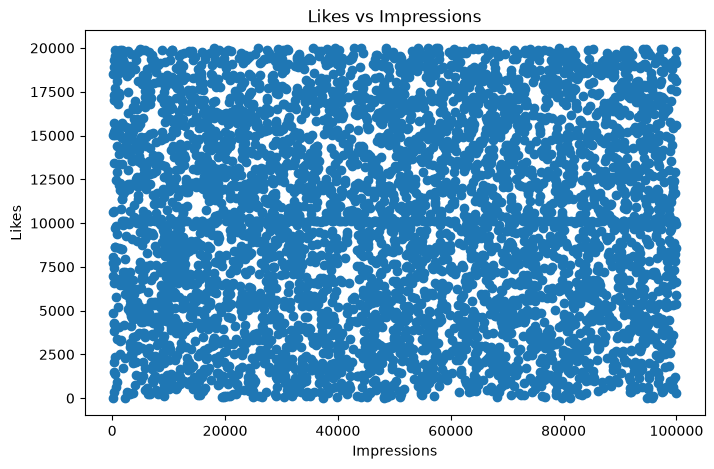

In [92]:
# Scatter: likes vs impressions


plt.figure(figsize=(8,5))

plt.scatter(df['impression_count'], df['likes'])

plt.xlabel('Impressions')
plt.ylabel('Likes')
plt.title('Likes vs Impressions')

plt.show()

In [93]:
# Line: daily engagement trend

daily_engagement = df.groupby(
    df['posted_at'].dt.date
)['engagement_score'].mean()

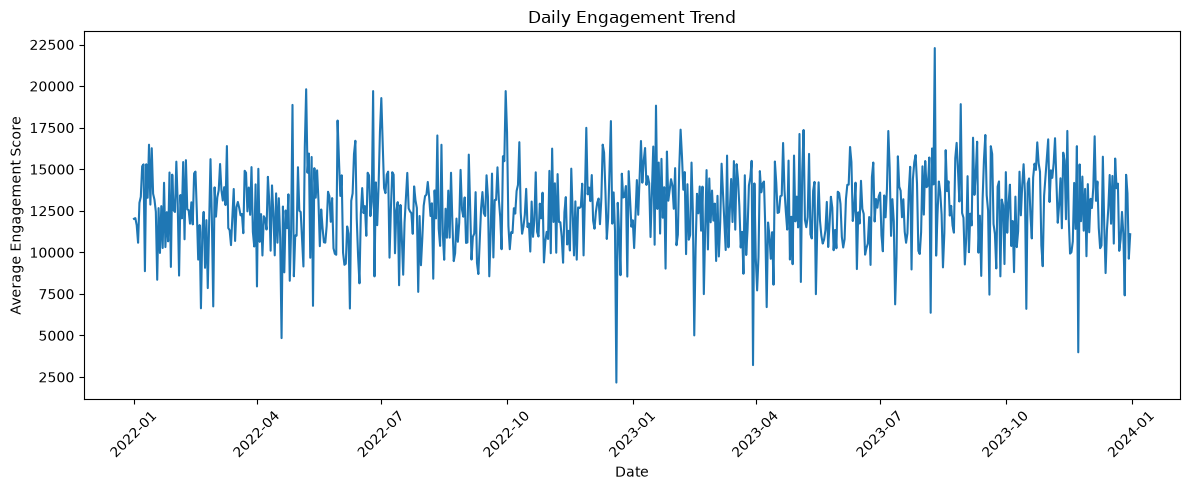

In [94]:
plt.figure(figsize=(12,5))

plt.plot(daily_engagement.index, daily_engagement.values)

plt.xlabel('Date')
plt.ylabel('Average Engagement Score')
plt.title('Daily Engagement Trend')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

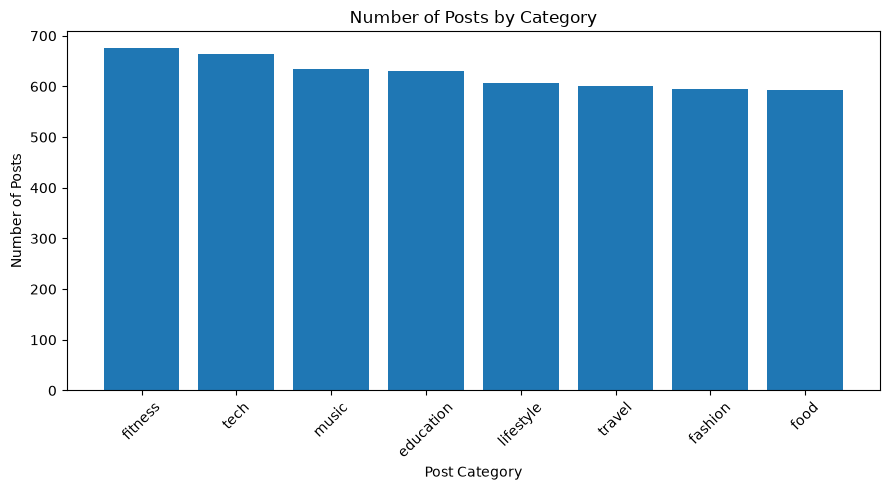

In [95]:
# Bar: posts by category

category_counts = df['post_category'].value_counts()

plt.figure(figsize=(9,5))

plt.bar(category_counts.index, category_counts.values)

plt.xlabel('Post Category')
plt.ylabel('Number of Posts')
plt.title('Number of Posts by Category')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

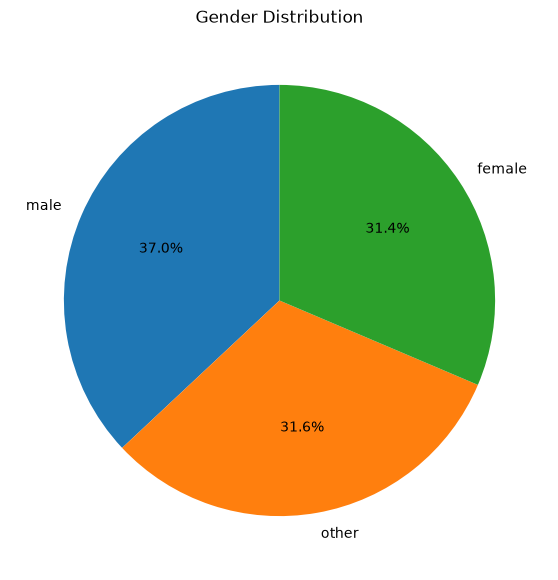

In [96]:
# Pie: gender distribution

gender_counts = df['gender'].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Gender Distribution')

plt.show()

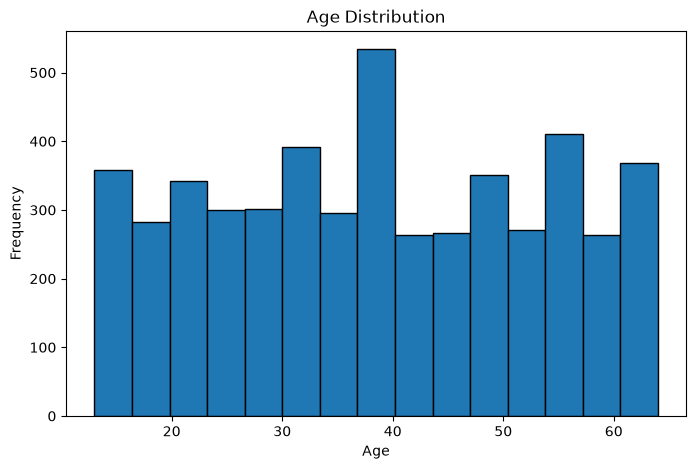

In [97]:
#Histogram: age

plt.figure(figsize=(8,5))

plt.hist(df['age'], bins=15, edgecolor='black')

plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution')

plt.show()

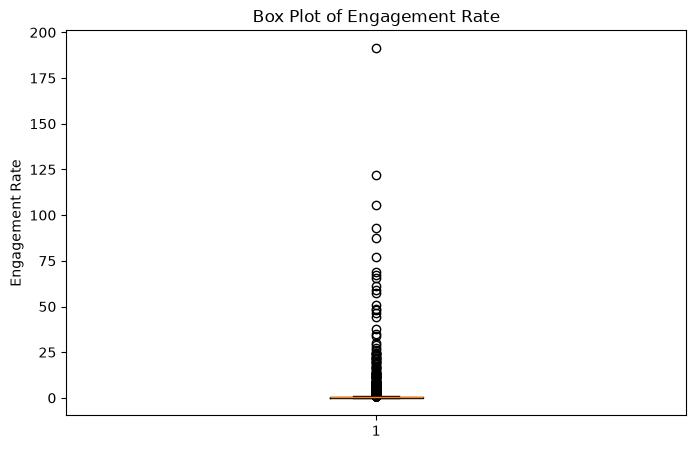

In [99]:
#Box: engagement rate

plt.figure(figsize=(8,5))

plt.boxplot(df['engagement_rate'].dropna())

plt.ylabel('Engagement Rate')
plt.title('Box Plot of Engagement Rate')

plt.show()

**Seaborn**

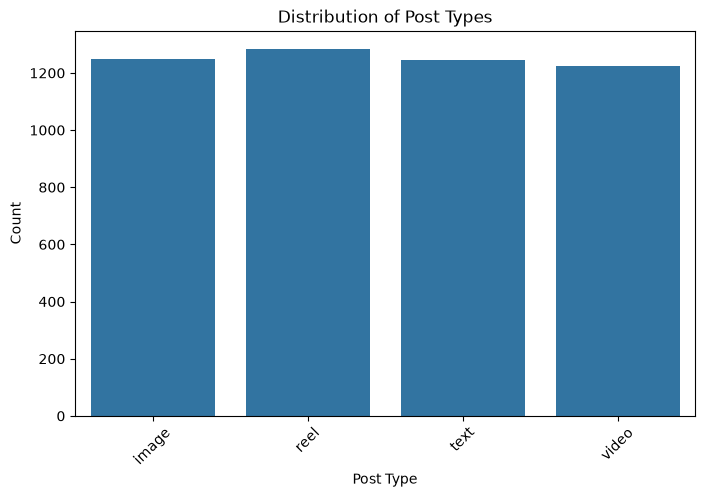

In [100]:
# Count plot: post type

plt.figure(figsize=(8,5))

sns.countplot(data=df, x='post_type')

plt.title('Distribution of Post Types')
plt.xlabel('Post Type')
plt.ylabel('Count')

plt.xticks(rotation=45)
plt.show()

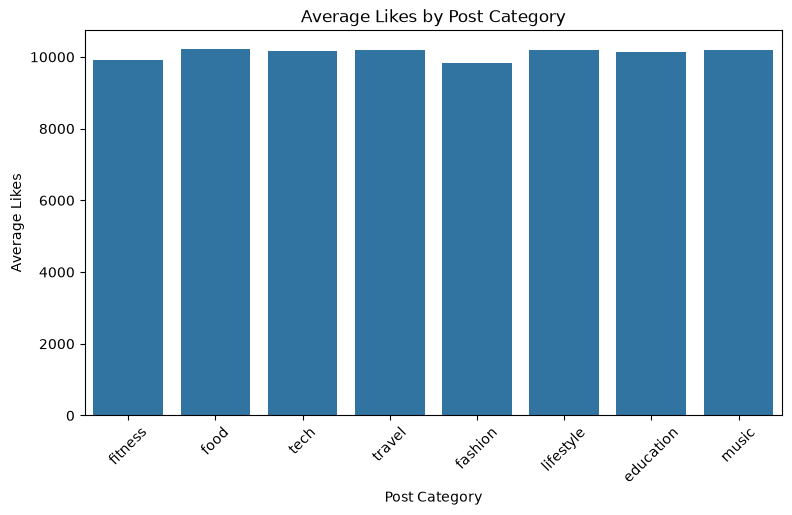

In [101]:
# Bar plot: avg likes by category

plt.figure(figsize=(9,5))

sns.barplot(
    data=df,
    x='post_category',
    y='likes',
    errorbar=None
)

plt.title('Average Likes by Post Category')
plt.xlabel('Post Category')
plt.ylabel('Average Likes')

plt.xticks(rotation=45)
plt.show()

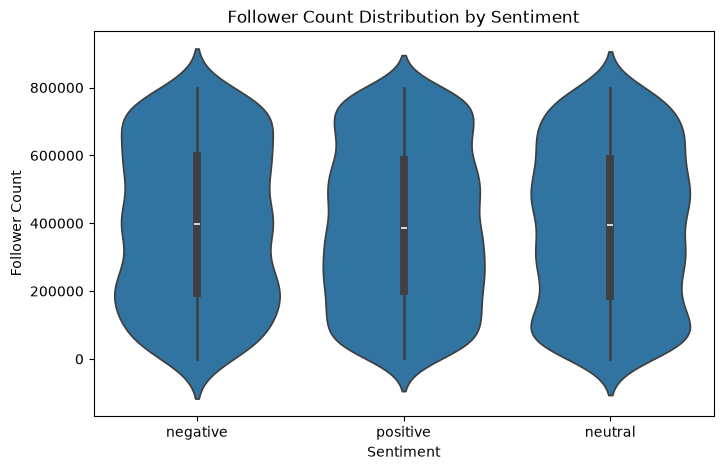

In [102]:
# Violin: followers vs sentiment

plt.figure(figsize=(8,5))

sns.violinplot(
    data=df,
    x='sentiment',
    y='follower_count'
)

plt.title('Follower Count Distribution by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Follower Count')

plt.show()

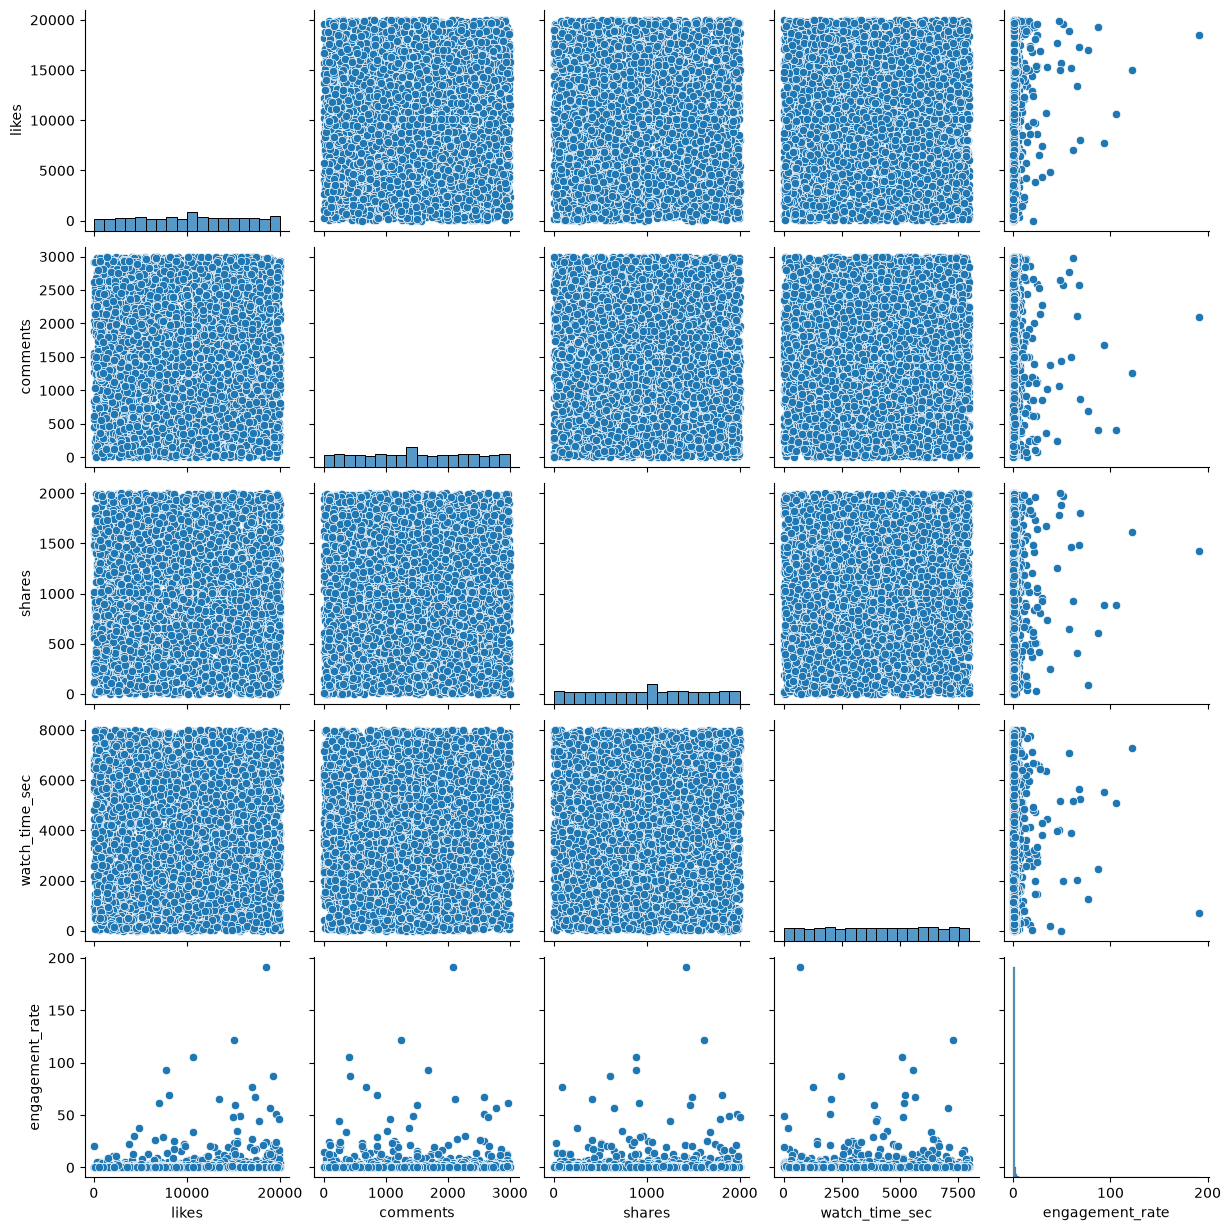

In [103]:
#Pair plot: numeric features

sns.pairplot(
    df[['likes', 'comments', 'shares',
        'watch_time_sec', 'engagement_rate']],
    diag_kind='hist'
)

plt.show()

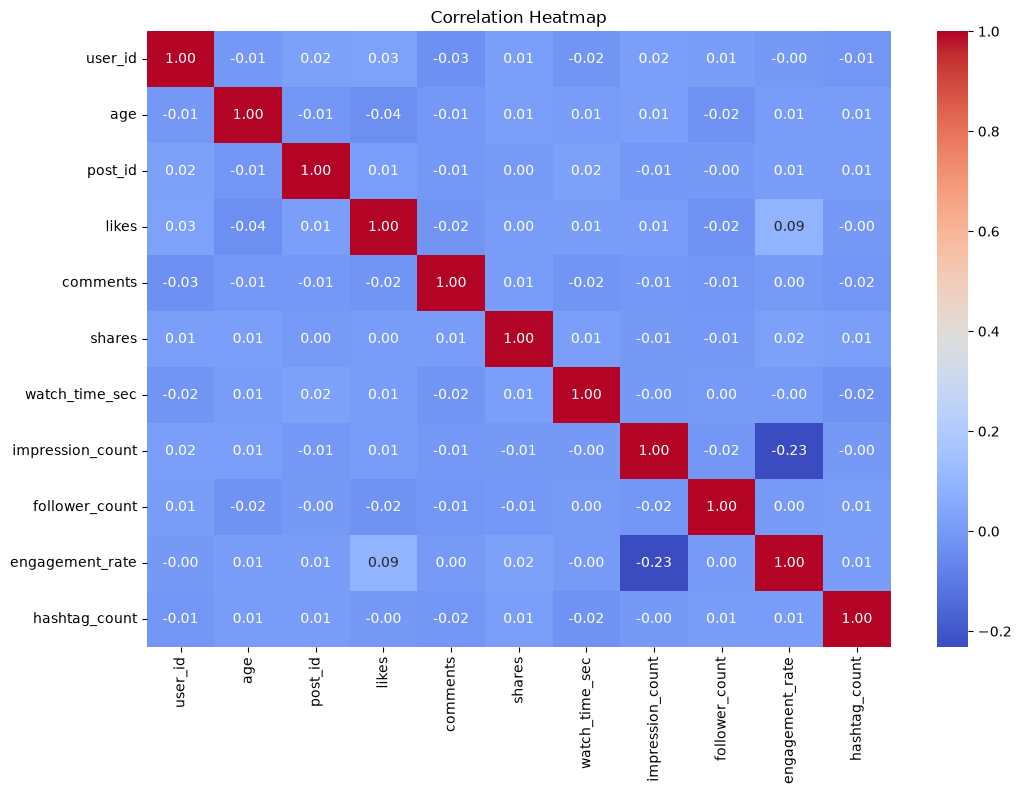

In [104]:
# Heatmap: correlation matrix

plt.figure(figsize=(12,8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

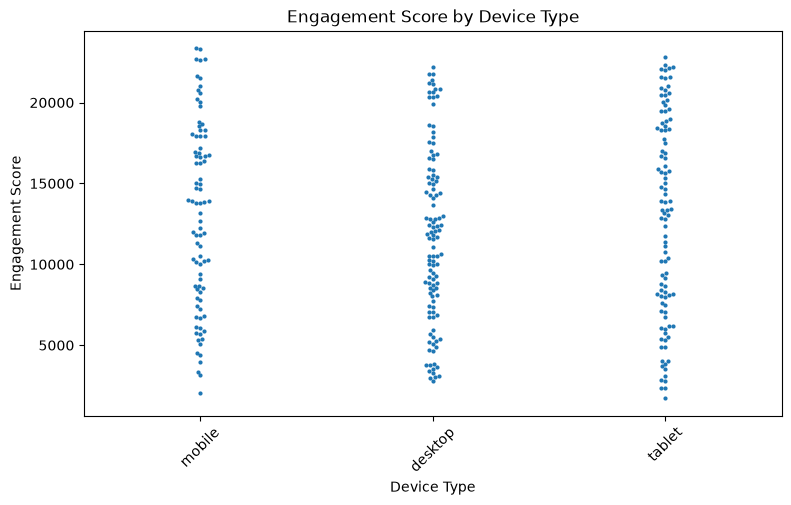

In [105]:
# Swarm plot: engagement vs device

sample_df = df.sample(
    n=min(300, len(df)),
    random_state=42
)

plt.figure(figsize=(9,5))

sns.swarmplot(
    data=sample_df,
    x='device_type',
    y='engagement_score',
    size=3
)

plt.title('Engagement Score by Device Type')
plt.xlabel('Device Type')
plt.ylabel('Engagement Score')

plt.xticks(rotation=45)
plt.show()

**Plotly (Interactive)**

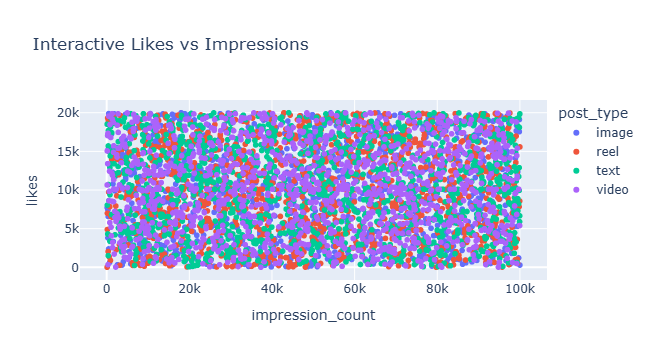

In [106]:
# Interactive line chart/bar chart/bubble/scatter char

fig = px.scatter(
    df,
    x='impression_count',
    y='likes',
    color='post_type',
    hover_data=['post_category', 'engagement_rate'],
    title='Interactive Likes vs Impressions'
)

fig.show()

## Final Insights

**Content Performance**

In [109]:
post_typeinsights = df.groupby('post_type').agg({
    'engagement_score': 'mean',
    'engagement_rate': 'mean',
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean'
}).sort_values(
    by='engagement_score',
    ascending=False
)

post_typeinsights

,engagement_score,engagement_rate,likes,comments,shares
post_type,,,,,
video,12664.594286,1.122365,10188.600000,1479.160000,996.834286
image,12649.390537,0.895646,10104.865277,1525.235766,1019.289495
text,12613.243775,1.064549,10100.148193,1499.106024,1013.989558
reel,12524.031567,0.783047,10037.802416,1504.187062,982.042089


In [110]:
category_insights = df.groupby('post_category').agg({
    'likes': 'mean',
    'engagement_score': 'mean',
    'engagement_rate': 'mean'
}).sort_values(
    by='engagement_rate',
    ascending=False
)

category_insights

,likes,engagement_score,engagement_rate
post_category,,,
food,10225.522766,12739.200675,1.358628
tech,10171.571429,12686.490226,1.160475
lifestyle,10180.559308,12639.539539,1.091019
music,10205.749606,12788.549606,0.888803
fitness,9914.602222,12457.791852,0.865628
education,10126.487322,12578.270206,0.844222
fashion,9843.356902,12356.420875,0.807109
travel,10196.304167,12650.559167,0.702223


In [111]:
country_insights = df.groupby('country')['engagement_rate'].mean().sort_values(
    ascending=False
)

country_insights

country
brazil       1.540704
australia    1.324339
france       1.146402
uae          1.112352
canada       0.916659
uk           0.850966
japan        0.769623
germany      0.759000
india        0.655005
usa          0.576580
Name: engagement_rate, dtype: float64

**User Trends**

In [112]:
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 18, 25, 35, 45, 60, 100],
    labels=['Below 18', '18-25', '26-35',
            '36-45', '46-60', 'Above 60']
)

In [113]:
age_insights = df.groupby('age_group', observed=True).agg({
    'engagement_score': 'mean',
    'engagement_rate': 'mean',
    'likes': 'mean'
})

age_insights

,engagement_score,engagement_rate,likes
age_group,,,
Below 18,12991.711538,0.867038,10495.145604
18-25,12628.408385,1.059536,10170.541925
26-35,12768.703874,0.865316,10240.393986
36-45,12741.579461,0.860741,10220.458643
46-60,12318.709538,1.152669,9796.227601
Above 60,12326.388889,0.801381,9901.868564


In [114]:
verified_insights = df.groupby('is_verified').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_score': 'mean',
    'engagement_rate': 'mean',
    'impression_count': 'mean'
})

verified_insights

,likes,comments,shares,engagement_score,engagement_rate,impression_count
is_verified,,,,,,
False,10137.201129,1505.511401,1001.599292,12644.311822,0.954744,49935.288244
True,9824.533126,1469.573499,1015.173913,12309.280538,1.054250,50747.343685


**Behavioral Insights**

In [115]:
df['posting_hour'] = df['posted_at'].dt.hour  #posyting hour

In [116]:
df['time_of_day'] = pd.cut(
    df['posting_hour'],
    bins=[-1, 5, 11, 17, 23],
    labels=['Night', 'Morning', 'Afternoon', 'Evening']  # time periods
)

In [117]:
time_insights = df.groupby('time_of_day', observed=True).agg({
    'impression_count': 'mean',
    'engagement_score': 'mean'
}).sort_values(
    by='impression_count',
    ascending=False
)

time_insights

,impression_count,engagement_score
time_of_day,,
Night,50013.7328,12611.9478


In [118]:
device_insights = df.groupby('device_type').agg({
    'watch_time_sec': 'mean',
    'engagement_score': 'mean',
    'engagement_rate': 'mean'
}).sort_values(
    by='watch_time_sec',
    ascending=False
)

device_insights

,watch_time_sec,engagement_score,engagement_rate
device_type,,,
mobile,4087.830760,12663.194477,1.123999
tablet,3979.736429,12463.280458,0.804560
desktop,3974.792521,12708.564837,0.962006


**Sentiment Analysis**

In [120]:
sentiment_insights = df.groupby('sentiment').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_score': 'mean',
    'engagement_rate': 'mean',
    'impression_count': 'mean'
})

sentiment_insights

,likes,comments,shares,engagement_score,engagement_rate,impression_count
sentiment,,,,,,
negative,10208.096875,1516.094792,1007.307292,12731.498958,1.038486,50191.960417
neutral,9923.194499,1528.404060,996.565160,12448.163720,0.991170,49515.971185
positive,10180.062077,1480.650617,1005.086749,12665.799443,0.919744,50248.107441


In [122]:
negative_neutral = df[
    df['sentiment'].isin(['negative', 'neutral'])
]

negative_neutral.groupby('sentiment').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_score': 'mean',
    'engagement_rate': 'mean'
})

,likes,comments,shares,engagement_score,engagement_rate
sentiment,,,,,
negative,10208.096875,1516.094792,1007.307292,12731.498958,1.038486
neutral,9923.194499,1528.404060,996.565160,12448.163720,0.991170


In [123]:
final_summary = pd.DataFrame({
    'Analysis': [
        'Best Post Type',
        'Best Content Category',
        'Top Country',
        'Best Age Group',
        'Best Performing Account Type',
        'Best Time for Impressions',
        'Best Device for Watch Time',
        'Best Performing Sentiment'
    ],
    'Result': [
        post_type_insights['engagement_score'].idxmax(),
        category_insights['engagement_rate'].idxmax(),
        country_insights.idxmax(),
        age_insights['engagement_score'].idxmax(),
        verified_insights['engagement_score'].idxmax(),
        time_insights['impression_count'].idxmax(),
        device_insights['watch_time_sec'].idxmax(),
        sentiment_insights['engagement_score'].idxmax()
    ]
})

final_summary

,Analysis,Result
0,Best Post Type,video
1,Best Content Category,food
2,Top Country,brazil
3,Best Age Group,Below 18
4,Best Performing Account Type,False
5,Best Time for Impressions,Night
6,Best Device for Watch Time,mobile
7,Best Performing Sentiment,negative


In [124]:
df.groupby('post_type')['engagement_rate'].mean().sort_values(ascending=False)

post_type
video    1.122365
text     1.064549
image    0.895646
reel     0.783047
Name: engagement_rate, dtype: float64